In [59]:
import pandas as pd
import requests
import numpy as np
import matplotlib.pyplot as plt
import datetime as dt
import seaborn as sns

In [63]:
stats = pd.read_csv('skater_summary.csv')
skaters = pd.read_csv('skaters.csv')
bdays = skaters[['id', 'birthDate']]
stats = pd.merge(stats, bdays, left_on = 'skaterId', right_on = 'id', how = 'left')
stats['season'] = stats['season'].astype(str)
stats['birthDate'] = pd.to_datetime(stats['birthDate'])
stats['birthDate'] = stats['birthDate'].dt.year
stats['Age'] = stats['season'].str[:4].astype(int) - stats['birthDate']
stats = stats.dropna()
stats['Age'] = stats['Age'].astype(int)
stats = stats.drop(columns = ['id'])

<Axes: xlabel='Age', ylabel='points'>

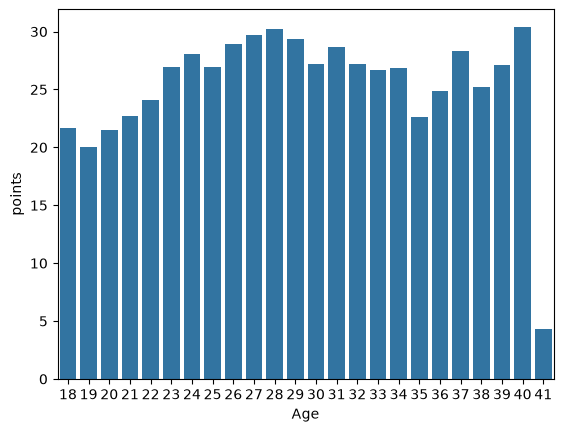

In [67]:
sns.barplot(stats.groupby('Age')['points'].mean())

In [82]:
stats.groupby('Age')['points'].mean()

Age
18    21.706897
19    20.071066
20    21.480226
21    22.677560
22    24.123574
23    26.925094
24    28.047273
25    26.909427
26    28.957576
27    29.745495
28    30.182482
29    29.367521
30    27.208054
31    28.700855
32    27.185185
33    26.692308
34    26.888889
35    22.589041
36    24.840909
37    28.320000
38    25.200000
39    27.125000
40    30.400000
41     4.333333
Name: points, dtype: float64

Performance peaks around 28, with average points increasing about 50% from 18 to 28 years. Performance then steadily decreases every year after that. This equates to roughly a 4% improvement year to year from 18 to 28.

In [80]:
test = stats[stats['skaterId'] == 8471214][['season', 'shootingPctg', 'goals']]

In [81]:
test

,season,shootingPctg,goals
5933,20052006,0.122400,52
5934,20062007,0.117300,46
5935,20072008,0.145700,65
5936,20082009,0.106100,56
5937,20092010,0.135900,50
5938,20102011,0.087200,32
5939,20112012,0.125400,38
5940,20122013,0.145500,32
5941,20132014,0.132100,51
5942,20142015,0.134200,53
